In [31]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [11]:
df = pd.read_csv(r"/Temperatures.csv")
print(df.head())

   YEAR    JAN    FEB    MAR    APR    MAY    JUN    JUL    AUG    SEP    OCT  \
0  1901  22.40  24.14  29.07  31.91  33.41  33.18  31.21  30.39  30.47  29.97   
1  1902  24.93  26.58  29.77  31.78  33.73  32.91  30.92  30.73  29.80  29.12   
2  1903  23.44  25.03  27.83  31.39  32.91  33.00  31.34  29.98  29.85  29.04   
3  1904  22.50  24.73  28.21  32.02  32.64  32.07  30.36  30.09  30.04  29.20   
4  1905  22.00  22.83  26.68  30.01  33.32  33.25  31.44  30.68  30.12  30.67   

     NOV    DEC  ANNUAL  JAN-FEB  MAR-MAY  JUN-SEP  OCT-DEC  
0  27.31  24.49   28.96    23.27    31.46    31.27    27.25  
1  26.31  24.04   29.22    25.75    31.76    31.09    26.49  
2  26.08  23.65   28.47    24.24    30.71    30.92    26.26  
3  26.36  23.63   28.49    23.62    30.95    30.66    26.40  
4  27.52  23.82   28.30    22.25    30.00    31.33    26.57  


In [12]:
df = df.drop_duplicates()

In [13]:
print("missing values")
print(df.isnull().sum())

missing values
YEAR       0
JAN        0
FEB        0
MAR        0
APR        0
MAY        0
JUN        0
JUL        0
AUG        0
SEP        0
OCT        0
NOV        0
DEC        0
ANNUAL     0
JAN-FEB    0
MAR-MAY    0
JUN-SEP    0
OCT-DEC    0
dtype: int64


In [14]:
print(df.duplicated().sum())

0


In [19]:
X = df.drop(columns=['YEAR', 'ANNUAL'])
y = df['ANNUAL'].apply(lambda x: 1 if x > df['ANNUAL'].mean() else 0)

In [30]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import(
    accuracy_score,
    confusion_matrix,
    precision_score,
    f1_score,
    recall_score,
    roc_curve,
    auc,
    RocCurveDisplay
)

In [22]:
splits=[0.25, 0.30, 0.40]

accuracy = []
models= []

for i in splits:
  X_train, X_test, y_train, y_test = train_test_split(X, y, test_size= i, random_state=42)

  model = DecisionTreeClassifier()
  model.fit(X_train, y_train)

  y_pred = model.predict(X_test)

  acc = accuracy_score(y_pred, y_test)
  accuracy.append(acc)

  models.append(model)

  print("Test size: ", i)
  print("Accuracy:", acc)

Test size:  0.25
Accuracy: 0.9333333333333333
Test size:  0.3
Accuracy: 0.8055555555555556
Test size:  0.4
Accuracy: 0.8297872340425532


In [25]:
for i in splits:
  print("Test size: ", i)
  print(confusion_matrix(y_pred, y_test))
  print()

Test size:  0.25
[[25  6]
 [ 2 14]]

Test size:  0.3
[[25  6]
 [ 2 14]]

Test size:  0.4
[[25  6]
 [ 2 14]]



In [26]:
for i in splits:
  print("Test size:", i)
  print("precisio=n score: ", precision_score(y_pred, y_test))
  print("recall score: ", recall_score(y_pred, y_test))
  print("F1 score: ", f1_score(y_pred, y_test))
  print()

Test size: 0.25
precisio=n score:  0.7
recall score:  0.875
F1 score:  0.7777777777777778

Test size: 0.3
precisio=n score:  0.7
recall score:  0.875
F1 score:  0.7777777777777778

Test size: 0.4
precisio=n score:  0.7
recall score:  0.875
F1 score:  0.7777777777777778



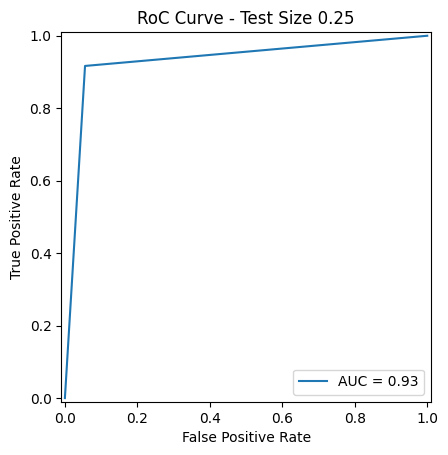

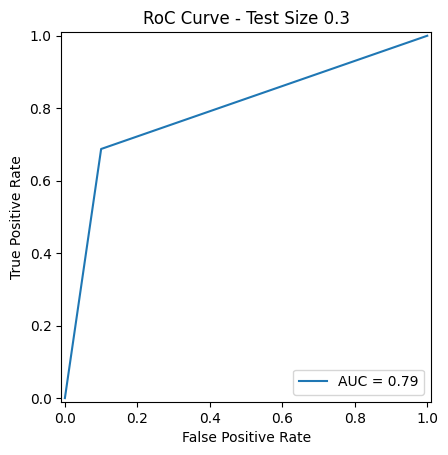

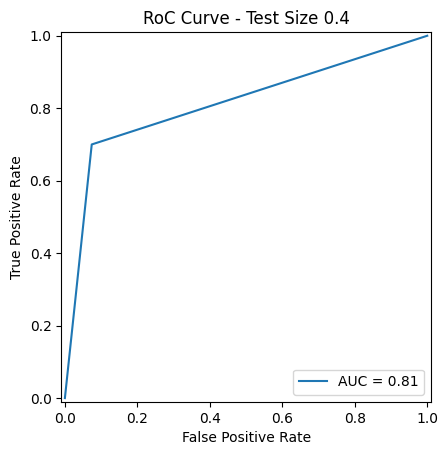

In [33]:
#roc curve
for i in splits:
  _, X_test_split, _, y_test_split = train_test_split(X,y,test_size =i, random_state=42)

  y_proba = models[splits.index(i)].predict_proba(X_test_split)[:, 1]
  fpr, tpr, thresholds = roc_curve(y_test_split, y_proba)
  auc_score = auc(fpr, tpr)

  display = RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc = auc_score)
  display.plot()
  plt.title(f"RoC Curve - Test Size {i}")
  plt.show()

In [34]:
best_acc = 0
best_split = None

for i in splits:
  idx = splits.index(i)
  acc = accuracy[idx]
  if acc > best_acc:
    best_acc = acc
    best_split = i

print(f"Best Accuracy: {best_acc:.4f} achieved with Test Size: {best_split}")

Best Accuracy: 0.9333 achieved with Test Size: 0.25


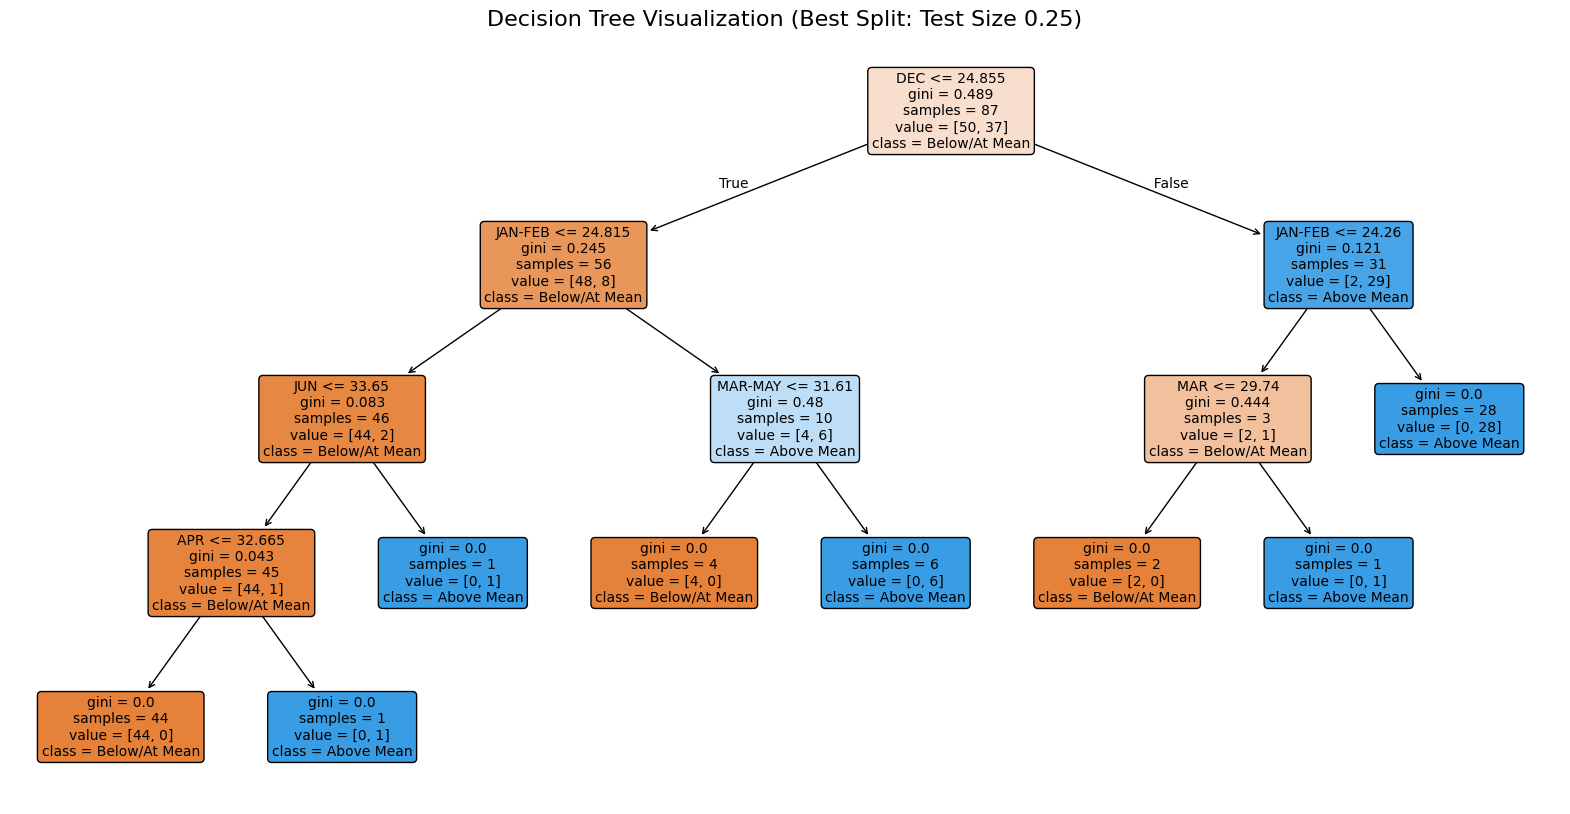

In [35]:
plt.figure(figsize=(20, 10))
plot_tree(
    models[0],
    feature_names=X.columns.tolist(),
    class_names=['Below/At Mean', 'Above Mean'],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Decision Tree Visualization (Best Split: Test Size 0.25)", fontsize=16)
plt.show()

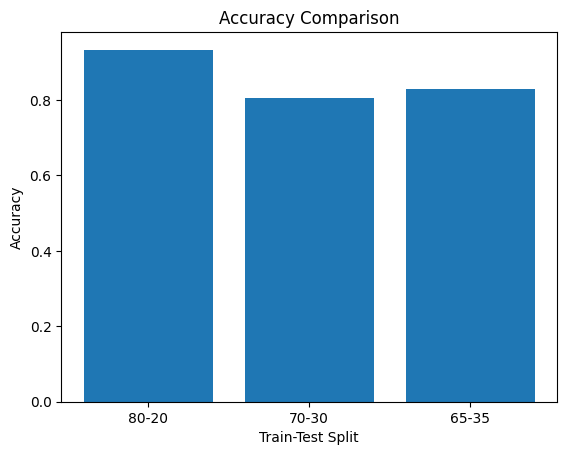

In [41]:
plt.bar(["80-20", "70-30", "65-35"], accuracy)

plt.xlabel("Train-Test Split")
plt.ylabel("Accuracy")
plt.title("Accuracy Comparison")

plt.show()